<a href="https://colab.research.google.com/github/AkshatkMalik/python-data-science-toolkit/blob/main/KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**ASSIGNMENT-15**

### Task 1 Overview
In this task, I will be loading the Zoo dataset and performing a detailed EDA[Educational Data Mining]. I will be using various plots to gain insight into:
1. The distribution of animal types(target variable).
2. The distribution of physical traits(features).
3. A correlation heatmap for the features.

Dataset Shape: (101, 18)


,animal name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,type
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1


/tmp/ipykernel_2082/2366748926.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='type', data=zoo_df, palette='Set2')


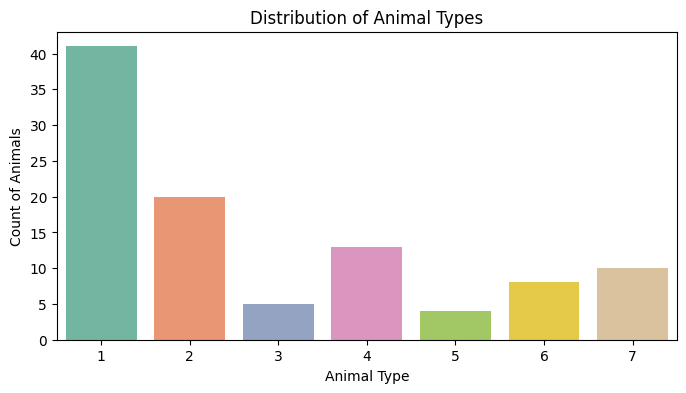

/tmp/ipykernel_2082/2366748926.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_sums.index, y=feature_sums.values, palette='viridis')


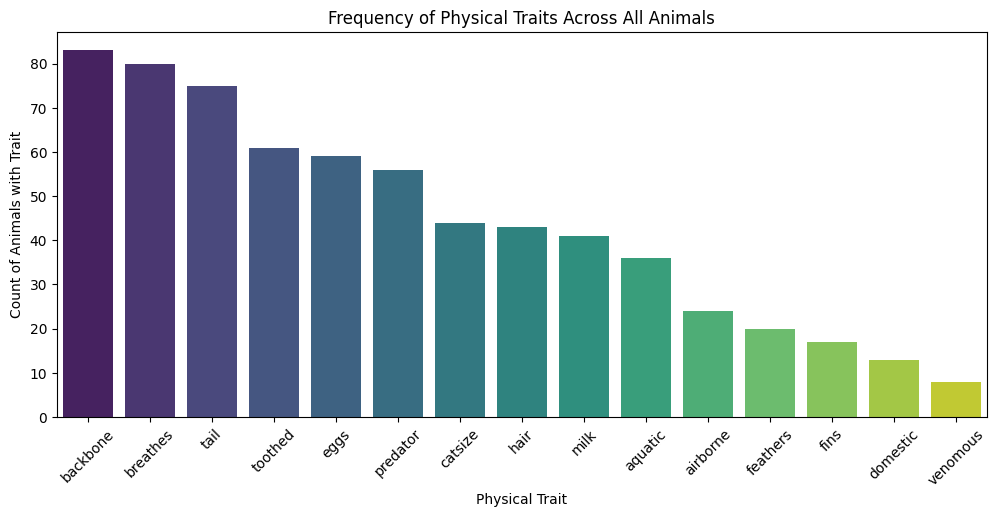

/tmp/ipykernel_2082/2366748926.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='legs', data=zoo_df, palette='muted')


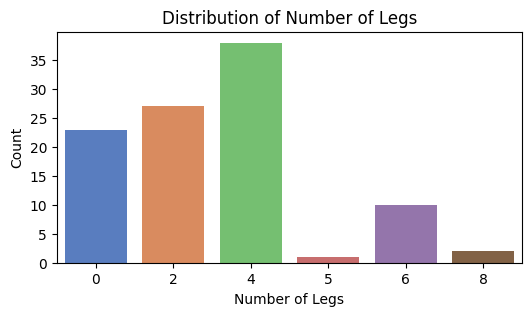

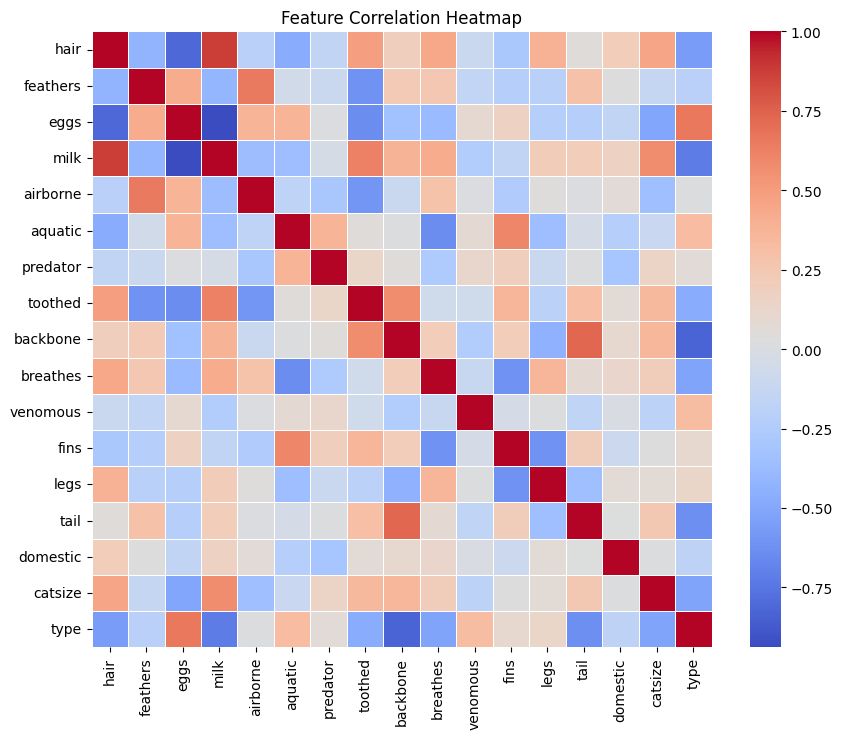

In [17]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
zoo_df = pd.read_csv('Zoo.csv')

# Display basic dataset information
print("Dataset Shape:", zoo_df.shape)
display(zoo_df.head())

# Visualization 1: Distribution of Animal Types (Target Variable)
plt.figure(figsize=(8, 4))
sns.countplot(x='type', data=zoo_df, palette='Set2')
plt.title('Distribution of Animal Types')
plt.xlabel('Animal Type')
plt.ylabel('Count of Animals')
plt.show()

# Visualization 2: Feature Frequency Plot (Sum of binary traits)
plt.figure(figsize=(12, 5))
feature_sums = zoo_df.drop(columns=['animal name', 'type', 'legs']).sum().sort_values(ascending=False)
sns.barplot(x=feature_sums.index, y=feature_sums.values, palette='viridis')
plt.title('Frequency of Physical Traits Across All Animals')
plt.xlabel('Physical Trait')
plt.ylabel('Count of Animals with Trait')
plt.xticks(rotation=45)
plt.show()

#  Visualization 3: Distribution of Legs
plt.figure(figsize=(6, 3))
sns.countplot(x='legs', data=zoo_df, palette='muted')
plt.title('Distribution of Number of Legs')
plt.xlabel('Number of Legs')
plt.ylabel('Count')
plt.show()

#  Visualization 4: Correlation Heatmap
plt.figure(figsize=(10, 8))
correlation_matrix = zoo_df.drop(columns=['animal name']).corr()
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

### Task 2: Data Preprocessing
In this stage, I have identified several missing values and outliers. As animal names are strings and cannot be used in a KNN algorithm (due to the computation of distances), I decided to remove this column and split the data into features (X) and targets (y).

Missing values count per column:
animal name    0
hair           0
feathers       0
eggs           0
milk           0
airborne       0
aquatic        0
predator       0
toothed        0
backbone       0
breathes       0
venomous       0
fins           0
legs           0
tail           0
domestic       0
catsize        0
type           0
dtype: int64
Total missing values: 0


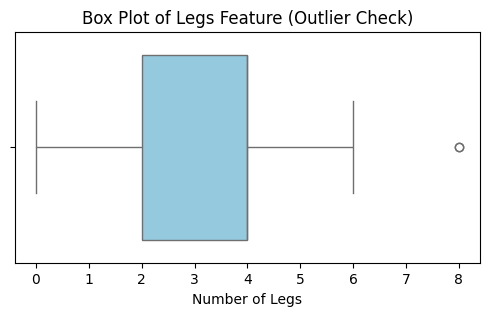

Preprocessing complete. Features shape: (101, 16)


In [18]:
# Check for missing values in the dataset
print("Missing values count per column:")
print(zoo_df.isnull().sum())
print("Total missing values:", zoo_df.isnull().sum().sum())

# Separate features (X) and target (y)
# We drop 'animal name' because text data cannot be processed directly by KNN distance metrics
X = zoo_df.drop(columns=['animal name', 'type'])
y = zoo_df['type']

# Optional check for outliers in numerical feature like 'legs' using boxplot
plt.figure(figsize=(6, 3))
sns.boxplot(x=zoo_df['legs'], color='skyblue')
plt.title('Box Plot of Legs Feature (Outlier Check)')
plt.xlabel('Number of Legs')
plt.show()

print("Preprocessing complete. Features shape:", X.shape)

### Task 3: Train-Test Split
In accordance with the assignment's requirements, we divided our preprocessed dataset into 80% training data (to train our KNN model) and 20% test data (to assess unseen performance) using train_test_split.



In [19]:
from sklearn.model_selection import train_test_split

# Split dataset: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Total training samples: {X_train.shape[0]} (80%)")
print(f"Total testing samples: {X_test.shape[0]} (20%)")

Total training samples: 80 (80%)
Total testing samples: 21 (20%)


### Task 4: Implement the KNN Algorithm

We import the `KNeighborsClassifier` from sklearn and fit (train) our model using the training data (`X_train`, `y_train`).

In [20]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize the KNN classifier
knn = KNeighborsClassifier()

# Fit/Train the model on the training dataset
knn.fit(X_train, y_train)

print("K-Nearest Neighbours model successfully trained on the training dataset!")

K-Nearest Neighbours model successfully trained on the training dataset!


### Task 5: Choose a Distance Metric and Value for K

Value for $K$ (`n_neighbors`): We choose $K=3$. A small $K$ helps capture local trends, and with only 101 samples in our data, $3$ is an optimal starting choice.

Distance Metric (`metric`): We'll use Euclidean distance (default standard in scikit-learn; think straight line distance).

In [21]:
# Re-initialize KNN with explicitly defined K=3 and Euclidean metric
optimal_k = 3
knn_optimized = KNeighborsClassifier(n_neighbors=optimal_k, metric='euclidean')
knn_optimized.fit(X_train, y_train)

print(f"KNN model updated with K = {optimal_k} and Euclidean distance metric.")

KNN model updated with K = 3 and Euclidean distance metric.


### Task 6: Model evaluation

We evaluate the quality of our trained classifier on the 20% test set, using Accuracy, Precision, Recall, and F1-score[cite: 2]. Since our problem is a multi-class classification (7 animal types), we set the `average='weighted'` parameter.

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Predict on test set
y_pred = knn_optimized.predict(X_test)

# Calculate metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}\n")

print("Detailed Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.9524
Precision: 0.9206
Recall   : 0.9524
F1-Score : 0.9333

Detailed Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      1.00      1.00         2
           3       0.00      0.00      0.00         1
           4       0.67      1.00      0.80         2
           6       1.00      1.00      1.00         3
           7       1.00      1.00      1.00         1

    accuracy                           0.95        21
   macro avg       0.78      0.83      0.80        21
weighted avg       0.92      0.95      0.93        21



### Task 7: Visualize the decision boundaries

To visualize the decision boundaries in a 2D space, we take 2 of the most prominent features (`legs` and `catsize`) from our training set and plot the decision boundaries[cite: 2].

<Figure size 900x500 with 0 Axes>

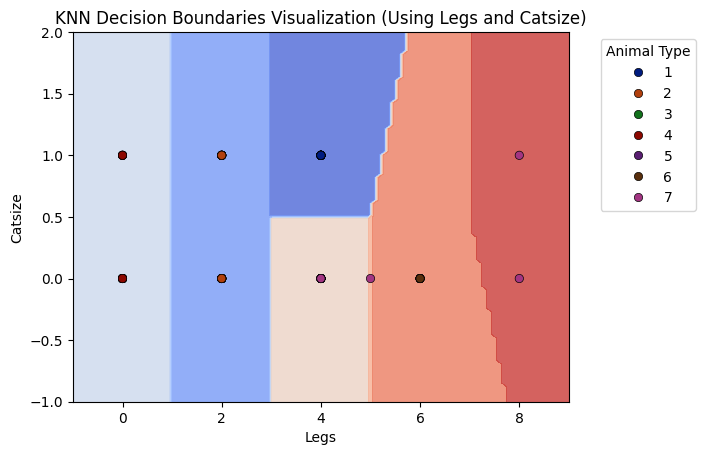

In [23]:
from sklearn.inspection import DecisionBoundaryDisplay

# Select 2 features for 2D visualization
X_vis = X_train[['legs', 'catsize']]
knn_vis = KNeighborsClassifier(n_neighbors=3, metric='euclidean')
knn_vis.fit(X_vis, y_train)

# Plot decision boundaries
plt.figure(figsize=(9, 5))
DecisionBoundaryDisplay.from_estimator(
    knn_vis, X_vis, response_method="predict", cmap=plt.cm.coolwarm, alpha=0.8, xlabel="Legs", ylabel="Catsize"
)
sns.scatterplot(x=X_vis['legs'], y=X_vis['catsize'], hue=y_train, palette='dark', edgecolor='k')
plt.title('KNN Decision Boundaries Visualization (Using Legs and Catsize)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Animal Type')
plt.show()

## Interview Questions

Q1. What are the key hyperparameters in KNN?


$K$ (`n_neighbors`): The number of nearest neighbors to be used for the classification/regression of a sample. Too low $K$ may lead to overfitting whereas too high $K$ may lead to underfitting.
Distance Metric (`metric`): The distance metric to be used in order to determine the distance between points. Few of the common distance metrics are Euclidean, Manhattan and Minkowski distance.
Weights (`weights`): The weights to be assigned to the neighbors. It can be either `uniform` (equal weights to all neighbors) or `distance` (neighbors with higher distance have higher influence on the output).

Q2. What distance metrics can be used in KNN?


Euclidean Distance: Calculates the straight line distance between two points.
Manhattan Distance: Calculates the distance between two points along the x and y axes.
Minkowski Distance: A generalization of both Euclidean and Manhattan distances.
Cosine Distance: Used to measure the cosine of the angle between two vectors. It is useful for distance computation in case of high dimensional data.